# UCS420 Lab Assignment 9 — NLP Text Preprocessing
Enter your roll number and name, then run all cells.

In [51]:
ROLL_NO = 1024170175          # <-- your full roll number
NAME = "Madhav"            # <-- your name

import nltk
for pkg in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4",
            "averaged_perceptron_tagger", "averaged_perceptron_tagger_eng"]:
    nltk.download(pkg, quiet=True)
assert ROLL_NO > 0 and NAME, "Enter your roll number and name first"

### Dataset generator — do not modify

In [52]:
import random, hashlib
import pandas as pd

def generate_dataset(roll_no):
    """Return (DataFrame of tickets, focus ticket IDs, fingerprint) for a roll number. Do not modify."""
    rng = random.Random(int(roll_no))

    subjects = [("LMS", ["LMS", "lms"]), ("Wi-Fi", ["Wi-Fi", "WiFi", "wifi"]), ("VPN", ["VPN"]),
                ("email", ["email", "e-mail"]), ("password", ["password"]), ("portal", ["student portal"]),
                ("projector", ["projector"]), ("laptop", ["laptop"]), ("MATLAB", ["MATLAB", "Matlab"]),
                ("Python", ["Python"]), ("printer", ["printer"]), ("server", ["server"])]
    actions = ["is not working", "keeps disconnecting", "failed to open", "is running slowly",
               "crashes while opening", "stopped responding", "is showing an error", "was working yesterday",
               "has stopped syncing", "keeps asking for login"]
    user_actions = ["cannot access", "can't open", "couldn't connect to", "am unable to use",
                    "tried restarting", "was locked out of", "keep getting logged out of", "reinstalled"]
    contexts = ["after resetting my password", "during the lab", "on my laptop", "since yesterday",
                "after the latest update", "when I use mobile hotspot", "before the assignment deadline",
                "while uploading the file", "after restarting the system", "when connected to campus Wi-Fi"]
    endings = ["Please help.", "Can you check this?", "I have tried several times!", "It worked yesterday.",
               "I don't know what changed.", "The same problem occurs again.", "Is there another solution?",
               "It works on another computer.", "This is urgent.", "Please resolve it."]
    challenges = {
        "negation": ["The Wi-Fi works, but the VPN doesn't.", "Why isn't the portal opening?",
                     "I can't login and I didn't change anything.", "It's not the laptop; it's the server.",
                     "Nothing works and nobody has replied.", "The printer won't print; it isn't jammed."],
        "numbers": ["Python 3.12 was installed yesterday.", "The file is 95.5% uploaded.",
                    "Error code 0x80070005 appears.", "I need Windows 11 by 5.30 p.m. today.",
                    "Only 2 of 30 PCs boot after 3.5 hours.", "Version 2.0.1 crashes at 99%."],
        "identifiers": ["Email me at helpdesk@university.edu.", "See https://lms.thapar.edu/help for details.",
                        "My roll no. is 1023-03-021.", "Ticket #4521 is still open.",
                        "Call me on +91 98765 43210 or 0175-239-3201.",
                        "Write to it.helpdesk@thapar.edu or visit www.thapar.edu/it."],
        "punctuation": ["I tried again... still no response!!!", "The LMS says 'Not Submitted'.",
                        "Dr. Rao's lab PC (No. 14) is down.", "Is it fixed?? Pls reply ASAP :(",
                        "The state-of-the-art lab (Lab-3) is closed.", "Re-installing didn't help; log-in still fails!"],
    }

    tickets = []
    for _ in range(8 + int(roll_no) % 5):
        _, variants = rng.choice(subjects)
        s = rng.choice(variants)
        template = rng.randrange(3)
        if template == 0:
            text = f"{s} {rng.choice(actions)} {rng.choice(contexts)}. {rng.choice(endings)}"
        elif template == 1:
            text = f"I {rng.choice(user_actions)} the {s} {rng.choice(contexts)}. {rng.choice(endings)}"
        else:
            text = f"The {s} {rng.choice(actions)}. {rng.choice(endings)}"
        tickets.append(text[0].upper() + text[1:])
    for category in ["negation", "numbers", "identifiers", "punctuation"]:
        tickets.append(rng.choice(challenges[category]))
    rng.shuffle(tickets)

    df = pd.DataFrame({"Ticket_ID": [f"T{i + 1:02d}" for i in range(len(tickets))], "Ticket_Text": tickets})
    focus = [f"T{i:02d}" for i in sorted(rng.sample(range(1, len(tickets) + 1), 2))]
    fingerprint = hashlib.md5(("|".join(tickets) + str(int(roll_no))).encode()).hexdigest()[:8].upper()
    return df, focus, fingerprint

### Preprocessing pipeline — do not modify

In [53]:
import string
from nltk.tokenize import sent_tokenize, word_tokenize
from nltk.corpus import stopwords

STOP = set(stopwords.words("english"))

def is_punct(token):
    """A token is punctuation if EVERY character in it is in string.punctuation (e.g. '.', '...', '``', "''")."""
    return all(ch in string.punctuation for ch in token)

def process_ticket(text):
    """The official pipeline. Returns sentences, lowercase tokens, punctuation, stopwords and final tokens."""
    sentences = sent_tokenize(text)
    tokens = [t.lower() for s in sentences for t in word_tokenize(s)]
    punct = [t for t in tokens if is_punct(t)]
    stops = [t for t in tokens if t in STOP]
    final = [t for t in tokens if not is_punct(t) and t not in STOP]
    return {"sentences": sentences, "tokens": tokens, "punct": punct, "stops": stops, "final": final}

In [54]:
df, FOCUS, FINGERPRINT = generate_dataset(ROLL_NO)
print(f"Roll number: {ROLL_NO}   Name: {NAME}   Fingerprint: {FINGERPRINT}   Tickets: {len(df)}\n")
print(df.to_string(index=False))
df.to_csv(f"{ROLL_NO}_generated_dataset.csv", index=False)

Roll number: 1024170175   Name: Madhav   Fingerprint: 22A3481D   Tickets: 12

Ticket_ID                                                                           Ticket_Text
      T01                                                    Dr. Rao's lab PC (No. 14) is down.
      T02            I tried restarting the projector while uploading the file. This is urgent.
      T03                                           I can't login and I didn't change anything.
      T04 Wifi was working yesterday when connected to campus Wi-Fi. Is there another solution?
      T05                                          See https://lms.thapar.edu/help for details.
      T06                                                        Error code 0x80070005 appears.
      T07           Laptop stopped responding after restarting the system. It worked yesterday.
      T08                Matlab stopped responding after resetting my password. This is urgent.
      T09                                I can't open the 

---
## Q1. Preprocessing pipeline
Run process_ticket() on every ticket and show one table with, per ticket: sentences, tokens, punctuation tokens, stopwords, unique tokens and final tokens, plus a TOTAL row.

In [55]:
results = []

for _, row in df.iterrows():
    processed = process_ticket(row["Ticket_Text"])
    results.append({
        "Ticket_ID": row["Ticket_ID"],
        "sentences": len(processed["sentences"]),
        "tokens": len(processed["tokens"]),
        "punctuation tokens": len(processed["punct"]),
        "stopwords": len(processed["stops"]),
        "unique tokens": len(set(processed["tokens"])),
        "final tokens": len(processed["final"])
    })

# Create table
result_df = pd.DataFrame(results)

# TOTAL row
total_row = {
    "Ticket_ID": "TOTAL",
    "sentences": result_df["sentences"].sum(),
    "tokens": result_df["tokens"].sum(),
    "punctuation tokens": result_df["punctuation tokens"].sum(),
    "stopwords": result_df["stopwords"].sum(),
    "unique tokens": result_df["unique tokens"].sum(),
    "final tokens": result_df["final tokens"].sum()
}

result_df = pd.concat(
    [result_df, pd.DataFrame([total_row])],
    ignore_index=True
)

result_df

,Ticket_ID,sentences,tokens,punctuation tokens,stopwords,unique tokens,final tokens
0,T01,2,13,4,3,12,6
1,T02,2,14,2,6,12,6
2,T03,1,11,1,4,9,6
3,T04,2,15,2,5,15,8
4,T05,1,7,2,1,7,4
5,T06,1,5,1,0,5,4
6,T07,2,12,2,3,11,7
7,T08,2,12,2,4,11,6
8,T09,2,13,2,4,12,7
9,T10,2,12,2,5,10,5


**Observe:** Which final tokens in your data are not real words (e.g. n't, 's, ca)? Where do they come from?

*Your answer:*

---
## Q2. Regular expressions
On your raw tickets, use re.findall to extract: words longer than 5 letters; all numbers (keep 95.5 and 2.0.1 whole); capitalized words; words starting with a vowel. Then use re.sub to replace emails with <EMAIL>, URLs with <URL> and phone numbers with <PHONE>. Your patterns must also work on TEST_LINES (given in the notebook).

In [56]:
TEST_LINES = [
    "Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.",
    "Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.",
    "The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.",
]
import re

# Convert list into one string
text = "\n".join(TEST_LINES)

# 1. Words longer than 5 letters
long_words = re.findall(r'\b[A-Za-z]{6,}\b', text)

# 2. Numbers, decimals and version numbers
numbers = re.findall(r'\b\d+(?:\.\d+)+\b|\b\d+\b', text)

# 3. Capitalized words
capitalized_words = re.findall(r'\b[A-Z][a-z]*\b', text)

# 4. Words beginning with a vowel
vowel_words = re.findall(r'\b[AEIOUaeiou][A-Za-z]*\b', text)

# 5. Replace email addresses
text = re.sub(
    r'\b[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}\b',
    '<EMAIL>',
    text
)

# 6. Replace URLs
text = re.sub(
    r'https?://[^\s]+|www\.[^\s]+',
    '<URL>',
    text
)

# 7. Replace phone numbers
text = re.sub(
    r'(?:\+\d{1,3}[-.\s]?)?\d{5}[-.\s]?\d{5}\b|\b\d{4}[-.\s]\d{3}[-.\s]\d{4}\b',
    '<PHONE>',
    text
)

print("Long words:", long_words)
print("Numbers:", numbers)
print("Capitalized words:", capitalized_words)
print("Vowel words:", vowel_words)
print("After replacement:")
print(text)

Long words: ['helpdesk', 'thapar', 'thapar', 'thapar', 'Version']
Numbers: ['91', '98765', '43210', '91', '98765', '43210', '0175', '239', '3201', '2.0.1', '95.5', '1', '250', '5.30']
Capitalized words: ['Mail', 'Call', 'Version', 'Rs', 'The']
Vowel words: ['it', 'edu', 'or', 'a', 'univ', 'ac', 'in', 'edu', 'or', 'edu', 'it', 'or', 'is', 'of', 'art', 'isn', 'open', 'in', 'at']
After replacement:
Mail <EMAIL> or <EMAIL>; visit <URL> or <URL>
Call <PHONE>, <PHONE> or <PHONE>. Version 2.0.1 is 95.5% done; fee Rs 1,250.
The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.


**Observe:** How many of your capitalized words are capitalized only because they start a sentence?

*Your answer:*

---
## Q3. Custom tokenizer
Write my_tokenize(text) with one RegexpTokenizer pattern that keeps contractions (isn't), hyphenated words (Wi-Fi, state-of-the-art), decimals and versions (95.5, 2.0.1), emails, URLs and phone numbers as single tokens. Run it on TEST_LINES and on your tickets, and compare with word_tokenize.

In [57]:
import re
from nltk.tokenize import RegexpTokenizer, word_tokenize
TEST_LINES = [
    "Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.",
    "Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.",
    "The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.",
]
def my_tokenize(text):
    pattern = r"""
        https?://[^\s]+
        |www\.[^\s]+
        |[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}
        |(?:\+\d{1,3}[-.\s]?)?\d{5}[-.\s]?\d{5}
        |\d{4}[-.\s]\d{3}[-.\s]\d{4}
        |\d+(?:\.\d+)+
        |[A-Za-z]+(?:-[A-Za-z]+)+
        |[A-Za-z]+(?:'[A-Za-z]+)
        |[A-Za-z]+
        |\d+
    """

    tokenizer = RegexpTokenizer(pattern, flags=re.VERBOSE)
    return tokenizer.tokenize(text)


# Run on TEST_LINES
for line in TEST_LINES:
    print("\nMY TOKENIZER:")
    print(my_tokenize(line))

    print("WORD_TOKENIZE:")
    print(word_tokenize(line))



MY TOKENIZER:
['Mail', 'it.helpdesk@thapar.edu', 'or', 'a.b-c@dept.univ.ac.in', 'visit', 'https://lms.thapar.edu/help', 'or', 'www.thapar.edu/it.']
WORD_TOKENIZE:
['Mail', 'it.helpdesk', '@', 'thapar.edu', 'or', 'a.b-c', '@', 'dept.univ.ac.in', ';', 'visit', 'https', ':', '//lms.thapar.edu/help', 'or', 'www.thapar.edu/it', '.']

MY TOKENIZER:
['Call', '+91 98765 43210', '+91-98765-43210', 'or', '0175-239-3201', 'Version', '2.0.1', 'is', '95.5', 'done', 'fee', 'Rs', '1', '250']
WORD_TOKENIZE:
['Call', '+91', '98765', '43210', ',', '+91-98765-43210', 'or', '0175-239-3201', '.', 'Version', '2.0.1', 'is', '95.5', '%', 'done', ';', 'fee', 'Rs', '1,250', '.']

MY TOKENIZER:
['The', 'state-of-the-art', 'lab', "isn't", 'open', 'log-in', 'at', '5.30', 'p', 'm', "didn't", 'work']
WORD_TOKENIZE:
['The', 'state-of-the-art', 'lab', 'is', "n't", 'open', ';', 'log-in', 'at', '5.30', 'p.m.', 'did', "n't", 'work', '.']


**Observe:** How many of your tickets are tokenized differently by my_tokenize and word_tokenize?

*Your answer:*

---
## Q4. Stemming and lemmatization
On your unique final tokens, compare PorterStemmer, LancasterStemmer, a RegexpStemmer with a suffix rule you choose after looking at your own words, and WordNetLemmatizer with POS tags from nltk.pos_tag. Show a table of the words where the outputs differ.

In [58]:

import pandas as pd
import nltk
from nltk.stem import PorterStemmer, LancasterStemmer, RegexpStemmer, WordNetLemmatizer
from nltk import pos_tag
from nltk.corpus import wordnet

# Initialize stemmers and lemmatizer
porter = PorterStemmer()
lancaster = LancasterStemmer()
regexp_stemmer = RegexpStemmer(r"ing$|ed$|es$")
lemmatizer = WordNetLemmatizer()

# Get unique final tokens from the tickets
tokens = []
for ticket in df["Ticket_Text"]:
    tokens.extend(process_ticket(ticket)["final"])

unique_tokens = sorted(set(tokens))

# Convert POS tags to WordNet POS tags
def get_wordnet_pos(tag):
    if tag.startswith("J"):
        return wordnet.ADJ
    elif tag.startswith("V"):
        return wordnet.VERB
    elif tag.startswith("R"):
        return wordnet.ADV
    else:
        return wordnet.NOUN

# POS tagging
tagged_words = pos_tag(unique_tokens)

results = []

for word, tag in tagged_words:
    porter_word = porter.stem(word)
    lancaster_word = lancaster.stem(word)
    regex_word = regexp_stemmer.stem(word)
    lemma_word = lemmatizer.lemmatize(
        word, pos=get_wordnet_pos(tag)
    )

    # Keep only words whose outputs differ
    if len(set([
        porter_word, lancaster_word,
        regex_word, lemma_word
    ])) > 1:
        results.append({
            "Word": word,
            "POS Tag": tag,
            "Porter Stem": porter_word,
            "Lancaster Stem": lancaster_word,
            "Regex Stem": regex_word,
            "WordNet Lemma": lemma_word
        })

comparison_df = pd.DataFrame(results)
comparison_df


,Word,POS Tag,Porter Stem,Lancaster Stem,Regex Stem,WordNet Lemma
0,another,DT,anoth,anoth,another,another
1,anything,NN,anyth,anyth,anyth,anything
2,appears,VBZ,appear,appear,appears,appear
3,campus,VB,campu,camp,campus,campus
4,change,NN,chang,chang,change,change
5,code,NN,code,cod,code,code
6,details,NNS,detail,detail,details,detail
7,error,NN,error,er,error,error
8,file,NN,file,fil,file,file
9,https,NN,http,https,https,http


**Observe:** Give one over-stemming and one under-stemming example from your table.

*Your answer:*

Over-stemming: Lancaster Stemmer can reduce a word too aggressively, producing a stem that loses meaningful parts of the original word.

Under-stemming: WordNet Lemmatizer may leave a word unchanged when it cannot identify an appropriate grammatical form or when the word is already a valid lemma.

---
## Q5. Corpus statistics
Compute tokens, unique tokens and TTR for S1 (all tokens), S2 (no punctuation), S3 (final tokens) and S4 (S3 after Porter). Print the top 10 words of S1 and S3, plot log(rank) vs log(frequency) for S3, and print the top 5 bigrams of S1 and S3.

CORPUS STATISTICS


,Corpus,Tokens,Unique Types,TTR
0,S1 - All tokens,137,77,0.5620
1,S2 - No punctuation,113,72,0.6372
2,S3 - Final tokens,69,50,0.7246
3,S4 - Porter stemmed,69,49,0.7101



Top 10 words in S1
     Word  Frequency
        .         19
      the          7
       is          6
     this          5
        i          4
   urgent          4
yesterday          4
      n't          3
   laptop          3
  stopped          3

Top 10 words in S3
      Word  Frequency
    urgent          4
 yesterday          4
       n't          3
    laptop          3
   stopped          3
responding          3
restarting          2
        ca          2
     login          2
      wifi          2


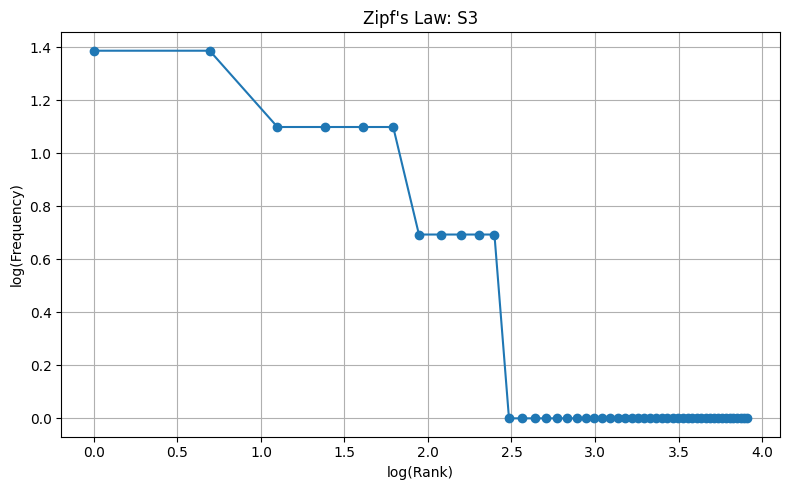


Top 5 bigrams in S1
   Bigram  Frequency
   . this          4
  this is          4
is urgent          4
 urgent .          4
      . i          3

Top 5 bigrams in S3
            Bigram  Frequency
stopped responding          3
         urgent ca          2
            ca n't          2
 working yesterday          2
           dr. rao          1


In [59]:

import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter
from nltk.stem import PorterStemmer
from nltk.util import bigrams
import math

# S1: All tokens, including punctuation
S1 = []
for ticket in df["Ticket_Text"]:
    S1.extend(process_ticket(ticket)["tokens"])

# S2: Tokens without punctuation
S2 = [word for word in S1 if not is_punct(word)]

# S3: Final tokens after stopword and punctuation removal
S3 = []
for ticket in df["Ticket_Text"]:
    S3.extend(process_ticket(ticket)["final"])

# S4: S3 after Porter stemming
porter = PorterStemmer()
S4 = [porter.stem(word) for word in S3]

# Token, type and TTR statistics
def corpus_stats(name, corpus):
    total_tokens = len(corpus)
    unique_types = len(set(corpus))
    ttr = unique_types / total_tokens if total_tokens else 0

    return {
        "Corpus": name,
        "Tokens": total_tokens,
        "Unique Types": unique_types,
        "TTR": round(ttr, 4)
    }

stats = pd.DataFrame([
    corpus_stats("S1 - All tokens", S1),
    corpus_stats("S2 - No punctuation", S2),
    corpus_stats("S3 - Final tokens", S3),
    corpus_stats("S4 - Porter stemmed", S4)
])

print("CORPUS STATISTICS")
display(stats)

# Top 10 words in S1
print("\nTop 10 words in S1")
print(pd.DataFrame(
    Counter(S1).most_common(10),
    columns=["Word", "Frequency"]
).to_string(index=False))

# Top 10 words in S3
print("\nTop 10 words in S3")
print(pd.DataFrame(
    Counter(S3).most_common(10),
    columns=["Word", "Frequency"]
).to_string(index=False))

# Zipf's law: log(rank) vs log(frequency) for S3
frequency = Counter(S3)
ranked_frequencies = sorted(frequency.values(), reverse=True)

ranks = range(1, len(ranked_frequencies) + 1)

plt.figure(figsize=(8, 5))
plt.plot(
    [math.log(rank) for rank in ranks],
    [math.log(freq) for freq in ranked_frequencies],
    marker="o"
)
plt.xlabel("log(Rank)")
plt.ylabel("log(Frequency)")
plt.title("Zipf's Law: S3")
plt.grid(True)
plt.tight_layout()
plt.show()

# Top 5 bigrams
def top_bigrams(corpus, name):
    counts = Counter(bigrams(corpus))

    print(f"\nTop 5 bigrams in {name}")
    print(pd.DataFrame(
        [
            (" ".join(pair), count)
            for pair, count in counts.most_common(5)
        ],
        columns=["Bigram", "Frequency"]
    ).to_string(index=False))

top_bigrams(S1, "S1")
top_bigrams(S3, "S3")


**Observe:** Why does TTR change from S1 to S4 in your data?

*Your answer:* Because TTR = Number of unique tokens/Total number of Tokens. S4 applies Porter stemming to the final tokens from S3.